### PHASE 1 — Data Audit & Risk Evaluation (Industrial Thinking)

##### Task 1: Data Integrity Check

In [1]:
import pandas as pd

In [2]:
df = pd.read_csv('ai4i2020.csv')

In [3]:
print("Missing values:")
print(df.isnull().sum())

Missing values:
UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64


In [4]:
print("\nChecking domain:")
print(f"Torque: from {df['Torque [Nm]'].min()} to {df['Torque [Nm]'].max()} Nm")
print(f"Air temperature: from {df['Air temperature [K]'].min()} to {df['Air temperature [K]'].max()} K")
print(f"Process temperature: from {df['Process temperature [K]'].min()} to {df['Process temperature [K]'].max()} K")


Checking domain:
Torque: from 3.8 to 76.6 Nm
Air temperature: from 295.3 to 304.5 K
Process temperature: from 305.7 to 313.8 K


"No negative torque and temperature is not outside the physical range"

In [5]:
print("\nDuplicates:", df.duplicated().sum())


Duplicates: 0


In [6]:
failure_cols = ['TWF', 'HDF', 'PWF', 'OSF', 'RNF']
df['sum_failures'] = df[failure_cols].sum(axis=1)

In [7]:
inc_1 = df[(df['sum_failures'] > 0) & (df['Machine failure'] == 0)]
inc_2 = df[(df['sum_failures'] == 0) & (df['Machine failure'] == 1)]

In [8]:
print(f"\nThere is a failure flag, but Machine failure = 0: {len(inc_1)} strings")
print(f"Machine failure = 1, but no failure flags: {len(inc_2)} strings")


There is a failure flag, but Machine failure = 0: 18 strings
Machine failure = 1, but no failure flags: 9 strings


##### Industrial Audit Summary (Deliverable)



*   Risk of unexplained breakdowns: In 9 instances, the machine failed without any specific cause flag being triggered, leaving real-time systems blind to the root cause.
*   False alarms and unnecessary halts: 18 records show random failure flags (RNF = 1) while the machine failure flag remains 0. Triggering automated stops on these flags causes unnecessary downtime.
*   Contaminated ML training data: Training predictive maintenance models on contradictory failure target labels will lower model accuracy and cause unpredictable predictions in production.
*   Limits of basic threshold checks: Single-variable sensor values look normal individually, meaning simple min/max rules won't catch impending failures.
*   Safety and cost implications: Relying on uncleaned sensor signals for automated actions increases the risk of unexpected breakdown costs or safety hazards on the plant floor.





### PHASE 2 — Sensor Behavior Analysis

In [9]:
# Firstly, we define sensors columns
sensors = [
    'Air temperature [K]',
    'Process temperature [K]',
    'Rotational speed [rpm]',
    'Torque [Nm]',
    'Tool wear [min]'
]

In [10]:
normal_df = df[df["Machine failure"] == 0]
failed_df = df[df["Machine failure"] == 1]

In [11]:
stats = []
for sensor in sensors:
    # IQR calculation
    iqr_norm = normal_df[sensor].quantile(0.75) - normal_df[sensor].quantile(0.25)
    iqr_fail = failed_df[sensor].quantile(0.75) - failed_df[sensor].quantile(0.25)

    stats.append({
        'Sensor': sensor,
        'Normal Mean ± Std': f"{normal_df[sensor].mean():.2f} ± {normal_df[sensor].std():.2f}",
        'Normal IQR': round(iqr_norm, 2),
        'Failed Mean ± Std': f"{failed_df[sensor].mean():.2f} ± {failed_df[sensor].std():.2f}",
        'Failed IQR': round(iqr_fail, 2),
        'Extreme Range': f"{df[sensor].min()} - {df[sensor].max()}"
    })

In [12]:
sensor_summary = pd.DataFrame(stats)
print(sensor_summary.to_string(index=False))

                 Sensor Normal Mean ± Std  Normal IQR Failed Mean ± Std  Failed IQR Extreme Range
    Air temperature [K]     299.97 ± 1.99         3.2     300.89 ± 2.07        3.40 295.3 - 304.5
Process temperature [K]     310.00 ± 1.49         2.3     310.29 ± 1.36        1.70 305.7 - 313.8
 Rotational speed [rpm]  1540.26 ± 167.39       186.0  1496.49 ± 384.94       95.00   1168 - 2886
            Torque [Nm]      39.63 ± 9.47        13.2     50.17 ± 16.37       15.25    3.8 - 76.6
        Tool wear [min]    106.69 ± 62.95       108.0    143.78 ± 72.76      123.00       0 - 253




*   **Which sensors behave differently before failure?**

Torque [Nm] and Rotational speed [rpm] show the most significant changes during breakdown states. Failed machines exhibit much higher average torque ($50.17 \text{ Nm}$ vs $39.63 \text{ Nm}$) and significantly higher dispersion in rotational speed (std jumps from $167.39$ to $384.94 \text{ rpm}$). Tool wear [min] is also noticeably higher in failed machines ($143.78 \text{ min}$ vs $106.69 \text{ min}$).
*   **Which variables may be early warning signals?**



1.   Torque spikes / high values serve as direct early warning indicators for mechanical strain and power failure modes.
2.   High Rotational Speed variance (extreme highs above 2500 rpm or low speeds under 1200 rpm) indicates operational instability.
3. Cumulative Tool Wear above 150 minutes signals an elevated risk of wear-related breakdown.





### PHASE 3 — Industrial Anomaly Detection

In [13]:
# Z-score Method (|Z| > 3)
z_scores = (df[sensors] - df[sensors].mean()) / df[sensors].std()
df['z_anomaly'] = (z_scores.abs() > 3).any(axis=1)

In [14]:
# IQR Method (< Q1 - 1.5*IQR or > Q3 + 1.5*IQR)
iqr_mask = pd.Series(False, index=df.index)
for col in sensors:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    iqr_mask |= (df[col] < (Q1 - 1.5 * IQR)) | (df[col] > (Q3 + 1.5 * IQR))

df['iqr_anomaly'] = iqr_mask

In [15]:
print("Z-score Anomalies")
print("Total anomalies detected:", df['z_anomaly'].sum())
print("Actual failures in Z anomalies:", df[df['z_anomaly']]['Machine failure'].sum())
print("Failure rate:", f"{df[df['z_anomaly']]['Machine failure'].mean():.2%}")

print("\nIQR Anomalies")
print("Total anomalies detected:", df['iqr_anomaly'].sum())
print("Actual failures in IQR anomalies:", df[df['iqr_anomaly']]['Machine failure'].sum())
print("Failure rate:", f"{df[df['iqr_anomaly']]['Machine failure'].mean():.2%}")

print("\nOverall dataset failure rate:", f"{df['Machine failure'].mean():.2%}")

Z-score Anomalies
Total anomalies detected: 178
Actual failures in Z anomalies: 46
Failure rate: 25.84%

IQR Anomalies
Total anomalies detected: 459
Actual failures in IQR anomalies: 72
Failure rate: 15.69%

Overall dataset failure rate: 3.39%


* Baseline failure rate: 3.39% across all 10,000 records.

* Z-score method: Detected 178 anomalies, and 46 of them failed. Failure rate in this zone is 25.84% (approx. 8x higher than average).   

* IQR method: Detected 459 anomalies, and 72 of them failed. Failure rate in this zone is 15.69% (approx. 5x higher than average).

* **Are anomalies noise or early breakdown signals?**

They are early breakdown signals, not random noise. The failure rate jumps from 3.39% normally up to 25.8% inside the anomaly zones. Extreme values in torque and speed directly correlate with actual machine breakdowns.   
* **Should we remove them or mark them as risk indicators?**
   
We should never remove them. In industrial predictive maintenance, removing extreme sensor values deletes the very patterns that predict failure. We need to keep them and engineer features that mark them as risk indicators.

#### Decision & Justification

We should retain all anomaly records in the dataset and flag them using risk indicators/features rather than dropping them.

**Why?**

Deleting anomalies would delete over 20% of the failure cases we want our ML model to detect.   
Sensors spiking (e.g., high torque or sudden speed drops) represents actual mechanical stress right before a crash. Creating binary flags like is_torque_extreme or is_speed_anomaly gives the machine learning model clear signals to catch breakdowns early.  

### PHASE 4 — Risk Segmentation (Business-Oriented)

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

In [17]:
# Tool Wear Risk Segmentation
def tool_wear_risk(val):
    if val <= 100:
        return 'Normal (0-100 min)'
    elif val <= 200:
        return 'Maintenance soon (100-200 min)'
    else:
        return 'Critical (200+ min)'

df['Tool_Wear_Risk'] = df['Tool wear [min]'].apply(tool_wear_risk)

In [18]:
# Temperature Difference Risk Segmentation (Process Temp - Air Temp)
df['temp_diff'] = df['Process temperature [K]'] - df['Air temperature [K]']

def temp_diff_risk(val):
    if val < 8.6:
        return 'Small (< 8.6 K - Dissipation Risk)'
    elif val <= 10.5:
        return 'Medium (8.6 - 10.5 K - Stable)'
    else:
        return 'Large (> 10.5 K - Overheating Risk)'

df['Temp_Diff_Risk'] = df['temp_diff'].apply(temp_diff_risk)

In [19]:
# Calculate Failure Rates per Risk Zone
tw_summary = df.groupby('Tool_Wear_Risk')['Machine failure'].agg(
    Total_Machines='count',
    Failures='sum',
    Failure_Rate_pct=lambda x: round(x.mean() * 100, 2)
).reset_index()

td_summary = df.groupby('Temp_Diff_Risk')['Machine failure'].agg(
    Total_Machines='count',
    Failures='sum',
    Failure_Rate_pct=lambda x: round(x.mean() * 100, 2)
).reset_index()

print("Tool Wear Risk Segmentation")
print(tw_summary.to_string(index=False))

print("\nTemperature Difference Risk Segmentation")
print(td_summary.to_string(index=False))

Tool Wear Risk Segmentation
                Tool_Wear_Risk  Total_Machines  Failures  Failure_Rate_pct
           Critical (200+ min)             762       118             15.49
Maintenance soon (100-200 min)            4571       116              2.54
            Normal (0-100 min)            4667       105              2.25

Temperature Difference Risk Segmentation
                     Temp_Diff_Risk  Total_Machines  Failures  Failure_Rate_pct
Large (> 10.5 K - Overheating Risk)            3689        82              2.22
     Medium (8.6 - 10.5 K - Stable)            5591       131              2.34
 Small (< 8.6 K - Dissipation Risk)             720       126             17.50


C:\Users\miros\AppData\Local\Temp\ipykernel_8628\3707844643.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=tw_plot_data.index, y=tw_plot_data['Failure_Rate_pct'], ax=axes[0], palette='Reds')
C:\Users\miros\AppData\Local\Temp\ipykernel_8628\3707844643.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=td_plot_data.index, y=td_plot_data['Failure_Rate_pct'], ax=axes[1], palette='Oranges')


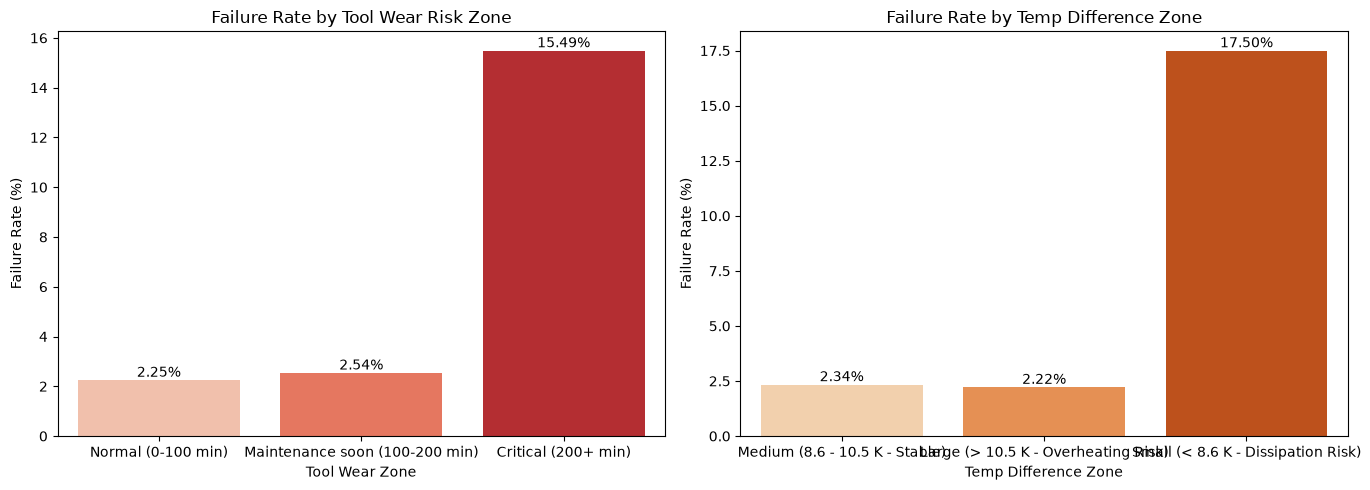

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Tool Wear
tw_plot_data = tw_summary.set_index('Tool_Wear_Risk').reindex(['Normal (0-100 min)', 'Maintenance soon (100-200 min)', 'Critical (200+ min)'])
sns.barplot(x=tw_plot_data.index, y=tw_plot_data['Failure_Rate_pct'], ax=axes[0], palette='Reds')
axes[0].set_title('Failure Rate by Tool Wear Risk Zone')
axes[0].set_ylabel('Failure Rate (%)')
axes[0].set_xlabel('Tool Wear Zone')
for p in axes[0].patches:
    axes[0].annotate(f'{p.get_height():.2f}%', (p.get_x() + p.get_width() / 2., p.get_height()), ha='center', va='center', xytext=(0, 5), textcoords='offset points')

# Plot 2: Temp Difference
td_plot_data = td_summary.set_index('Temp_Diff_Risk').reindex(['Medium (8.6 - 10.5 K - Stable)', 'Large (> 10.5 K - Overheating Risk)', 'Small (< 8.6 K - Dissipation Risk)'])
sns.barplot(x=td_plot_data.index, y=td_plot_data['Failure_Rate_pct'], ax=axes[1], palette='Oranges')
axes[1].set_title('Failure Rate by Temp Difference Zone')
axes[1].set_ylabel('Failure Rate (%)')
axes[1].set_xlabel('Temp Difference Zone')
for p in axes[1].patches:
    axes[1].annotate(f'{p.get_height():.2f}%', (p.get_x() + p.get_width() / 2., p.get_height()), ha='center', va='center', xytext=(0, 5), textcoords='offset points')

plt.tight_layout()
plt.show()

* **Does risk segmentation meaningfully separate failure probability?**

Yes, absolutely. Creating specific risk zones separates low-risk operational states from high-risk failure zones:   
1. For Tool Wear, entering the Critical Zone (200+ min) increases failure probability from ~2.2% to 15.49% (a 7x increase).   
2. For Temperature Difference, entering the Small Difference Zone (< 8.6 K) causes failure probability to jump from ~2.3% to 17.50% due to heat dissipation failures (HDF).   
3. These business-oriented categories allow maintenance engineers to schedule targeted repairs before machines reach critical threshold zones.

### PHASE 5 — Data Preparation for Production

In [21]:
from sklearn.preprocessing import RobustScaler

In [22]:
# Scaling
scaler = RobustScaler()
scaled_features = scaler.fit_transform(df[sensors])
df_scaled = pd.DataFrame(scaled_features, columns=[c + '_scaled' for c in sensors])

In [23]:
# Class imbalance
class_counts = df['Machine failure'].value_counts()
class_pct = df['Machine failure'].value_counts(normalize=True) * 100

print("Class Imbalance")
print(pd.DataFrame({'Count': class_counts, 'Percentage (%)': class_pct.round(2)}))

Class Imbalance
                 Count  Percentage (%)
Machine failure                       
0                 9661           96.61
1                  339            3.39


The dataset is highly imbalanced. Over 96.6% of records belong to normal operation, while only 3.39% represent machine failures.

In [24]:
# 30% Sampling
sample_30 = df.sample(frac=0.30, random_state=42)

In [25]:
# Full Dataset vs 30% Sample
full_stats = df[sensors + ['Machine failure']].agg(['mean', 'std']).T
sample_stats = sample_30[sensors + ['Machine failure']].agg(['mean', 'std']).T

comp_table = pd.DataFrame({
    'Full Mean': full_stats['mean'].round(2),
    'Full Std': full_stats['std'].round(2),
    'Sample Mean (30%)': sample_stats['mean'].round(2),
    'Sample Std (30%)': sample_stats['std'].round(2)
})

print("\nStatistics Comparison Table")
print(comp_table)


Statistics Comparison Table
                         Full Mean  Full Std  Sample Mean (30%)  \
Air temperature [K]         300.00      2.00             299.99   
Process temperature [K]     310.01      1.48             310.00   
Rotational speed [rpm]     1538.78    179.28            1540.87   
Torque [Nm]                  39.99      9.97              39.70   
Tool wear [min]             107.95     63.65             108.62   
Machine failure               0.03      0.18               0.03   

                         Sample Std (30%)  
Air temperature [K]                  2.01  
Process temperature [K]              1.47  
Rotational speed [rpm]             174.61  
Torque [Nm]                          9.85  
Tool wear [min]                     64.92  
Machine failure                      0.17  


* Why Robust was choosen?

As discovered in Phase 3, features like Rotational speed and Torque contain significant extreme outliers and anomalies. Standard scaling uses mean and standard deviation, which are heavily distorted by extreme values. RobustScaler uses the median and IQR, preserving sensor anomalies as true risk signals without distorting the feature scales.

* **If this dataset is used for model training, what bias risks exist?**

The main risk is that 96.6% of the data is normal machine operation, so the model could just predict 'no failure' every time and get high accuracy while missing all real breakdowns. Taking a basic 30% random sample makes the failure rate even lower, which risks dropping those already rare failure examples. Also, some specific failure types happen less than 1% of the time, so without special adjustments, the model will just ignore these important sensor signals.